# main: run the whole project in order

**Purpose.** One entry point that runs every step of the project top to bottom, so the results can be rebuilt with
*Restart, Run All* on this notebook only.

**Input.** Nothing beyond the repository and internet access for the first run (notebook 01 downloads the SEC and
FRED data; it needs `sec_user_agent.txt` in the repository root or the environment variable `SEC_USER_AGENT`, see
README).

**Output.** Everything the step notebooks write: `data/processed/`, `output/tables/`, `output/figures/`.

**Steps.**
1. `01_preprocess.ipynb`: working dataset of new BDC loans (about 25 minutes on a laptop, longer on the first run).
2. `02_estimate.ipynb`: model horse race on the validation folds (not written yet).
3. `03_evaluate.ipynb`: final evaluation on the test quarters, used once (not written yet).

## Step 1: preprocessing

project folder: DSF_Project
2022q4_bdc.zip     11.9
2023q1_bdc.zip     16.7
2023q2_bdc.zip     20.4
2023q3_bdc.zip     21.9
2023q4_bdc.zip     23.4
2024q1_bdc.zip     30.6
2024q2_bdc.zip     24.1
2024q3_bdc.zip     25.8
2024q4_bdc.zip     27.5
2025q1_bdc.zip     36.9
2025q2_bdc.zip     29.7
2025q3_bdc.zip     31.7
2025q4_bdc.zip     34.5
2026_01_bdc.zip     0.9
2026_02_bdc.zip    16.0
2026_03_bdc.zip    29.0
2026_04_bdc.zip     1.1
2026_05_bdc.zip    41.0
2026_06_bdc.zip     0.1
2026_07_bdc.zip     2.5
2026_08_bdc.zip    75.9
2026_09_bdc.zip     0.4
2026_10_bdc.zip     1.8


rows: 2035844  filings (adsh): 2310  BDCs (cik): 204


source_file
2022q4_bdc.zip      48
2023q1_bdc.zip      62
2023q2_bdc.zip     124
2023q3_bdc.zip     135
2023q4_bdc.zip     139
2024q1_bdc.zip     140
2024q2_bdc.zip     151
2024q3_bdc.zip     154
2024q4_bdc.zip     156
2025q1_bdc.zip     160
2025q2_bdc.zip     166
2025q3_bdc.zip     165
2025q4_bdc.zip     179
2026_01_bdc.zip      2
2026_02_bdc.zip     52
2026_03_bdc.zip    119
2026_04_bdc.zip      4
2026_05_bdc.zip    173
2026_07_bdc.zip      6
2026_08_bdc.zip    169
2026_09_bdc.zip      2
2026_10_bdc.zip      4


period-end months: {2: 1237, 3: 277813, 5: 1847, 6: 290617, 7: 215, 8: 2441, 9: 245044, 11: 1576, 12: 251826}


BDC-quarters with more than one filing: 12 (kept the latest filing)
         bdcs  filings   rows
quarter                      
2022Q3     49       49  31027
2022Q4     65       65  29841
2023Q1    123      123  47675
2023Q2    134      134  49342
2023Q3    140      140  53639
2023Q4    143      143  55655
2024Q1    149      149  59650
2024Q2    154      154  63475
2024Q3    158      158  68507
2024Q4    160      160  71487
2025Q1    165      165  75627
2025Q2    165      165  80294
2025Q3    167      167  87288
2025Q4    173      173  93515
2026Q1    174      174  96098
2026Q2    175      175  99257


BDCs: 204  families: 103  families with >1 BDC: 45
family
AG Twin Brook                                                                  [AG TWIN BROOK BDC, INC., TPG TWIN BROOK CAPITAL INCOME FUND]
AllianceBernstein                                                                [AB PRIVATE CREDIT INVESTORS CORP, AB PRIVATE LENDING FUND]
Antares                                   [ANTARES PRIVATE CREDIT FUND, ANTARES STRATEGIC CREDIT FUND, ANTARES STRATEGIC CREDIT FUND II LLC]
Apollo               [APOLLO DEBT SOLUTIONS BDC, APOLLO ORIGINATION II (LEVERED) CAPITAL TRUST, APOLLO ORIGINATION II (UL) CAPITAL TRUST,...
Ares                                                          [ARES CAPITAL CORP, ARES CORE INFRASTRUCTURE FUND, ARES STRATEGIC INCOME FUND]
Audax                                                                                [AUDAX CREDIT BDC INC., AUDAX PRIVATE CREDIT FUND, LLC]
BC Partners                                                       [BC PARTNERS LENDING CORP, BCP

... (22 outputs left out)

loans_incl_refi.csv: display names cleaned for 39 loans
variant incl. refinancings: (2171, 56)


core: (1725, 54)  all-BDC: (7174, 54)
       loans   first    last
split                       
test     594  2025Q3  2026Q2
train   1131  2023Q2  2025Q2
       spread_pp  tenor_years  log_principal  baa_spread_prev  sofr_prev  mkt_spread_t2_all
count    1725.00      1725.00        1725.00          1725.00    1725.00            1725.00
mean        4.82         6.33          16.14             1.66       4.69               5.10
std         1.23         0.84           1.47             0.14       0.56               0.53
min         1.75         4.06          11.51             1.42       3.68               4.50
25%         4.25         5.66          15.20             1.55       4.41               4.75
50%         5.00         6.23          16.18             1.67       4.49               5.00
75%         5.50         7.12          17.11             1.76       5.33               5.25
max         9.50         7.50          20.48             2.11       5.38               6.75
missing values (co

                                      1_candidates  2_complete_prev_q  3_not_held_before  4_new_rule  5_final_core
family                                                                                                            
Apollo                                        7360               7108                638         638           334
Goldman Sachs                                 7626               7404                589         589           190
BlackRock                                     4046               3851                288         288           128
Antares                                       3755               3480                250         250           119
First Eagle                                   1123               1099                184         184            92
Bain Capital                                  2582               2483                215         215            76
Jefferies                                     1306               1264           

      count   25%   50%   75%
year                         
2023  183.0  5.75  6.10  6.55
2024  655.0  4.25  5.00  5.55
2025  614.0  4.00  4.75  5.25
2026  273.0  3.25  4.50  5.00
                        count   25%   50%   75%
sector                                         
Industrials             510.0  4.50  5.00  5.50
Health Care             270.0  4.50  5.00  5.50
Information Technology  269.0  4.50  5.00  5.75
Consumer Discretionary  236.0  4.00  5.00  5.75
Financials              140.0  3.25  4.50  5.25
Consumer Staples         80.0  4.50  5.00  5.75
Materials                75.0  3.50  4.75  5.25
Communication Services   72.0  3.50  4.80  6.00
Energy                   45.0  2.75  3.75  5.50
Utilities                17.0  3.00  3.50  5.25
Real Estate              11.0  5.00  5.50  5.75
                                count   50%
family                                     
Apollo                          334.0  4.75
Goldman Sachs                   190.0  4.75
BlackRock           

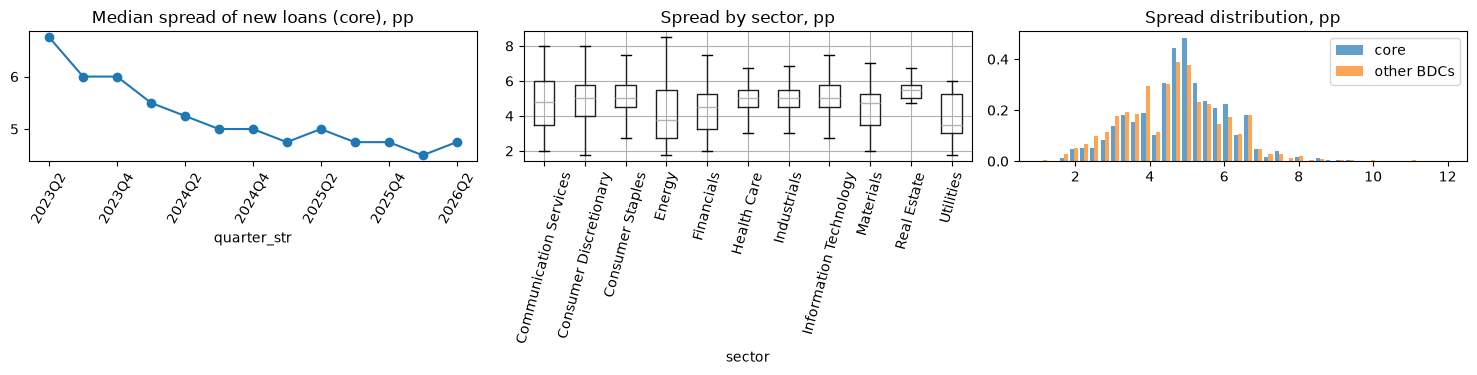

                         feature                                                           value fixed by                            check
                     tenor_years                              computed from quarter_start (contract term)                  by construction
                   log_principal held principal at the reporting date (approximation of the planned hold)                  by construction
sector, lien, instrument, family                  contract characteristics, fixed when the deal is signed                  by construction
      baa_spread_prev, sofr_prev                                    FRED value dated before quarter_start                             True
               mkt_spread_t2_all                          loans of quarter t-2 filed before quarter_start asserted below for every quarter
t-2 market median and FRED dates checked for 13 quarters


checked loans whose loan_id changed since the check (family re-mapping): 5
hand-checked loans: 50  families: 29  still in the final sample: 36
found_in_filing  matches: 50 of 50 (others: value tagged in XBRL but not printed next to the name)
spread_ok        matches: 50 of 50 (others: value tagged in XBRL but not printed next to the name)
maturity_ok      matches: 49 of 50 (others: value tagged in XBRL but not printed next to the name)
principal_ok     matches: 50 of 50 (others: value tagged in XBRL but not printed next to the name)
industry_ok      matches: 48 of 50 (others: value tagged in XBRL but not printed next to the name)


Patrick's hand-checked loans: 50  in our final sample: 26  classes there: {'a': 25, 'b': 1}  classes of the others: {'a': 16, 'b': 8}


verification sample: 30  in the final sample: 29  classes: {'a': 24, 'b': 5, 'not new (restructuring)': 1}
loans checked more than once: 0
                                                  sample class  n  share  ci_low  ci_high
                                        all checked (50)     a 35  0.700   0.562    0.809
                                        all checked (50)     b 14  0.280   0.175    0.417
                                        all checked (50)     c  1  0.020   0.004    0.105
                                    in final sample (36)     a 32  0.889   0.747    0.956
                                    in final sample (36)     b  3  0.083   0.029    0.218
                                    in final sample (36)     c  1  0.028   0.005    0.142
                           Patrick, in final sample (26)     a 25  0.962   0.811    0.993
                           Patrick, in final sample (26)     b  1  0.038   0.007    0.189
                           Patrick, in final sample

                            count   25%  50%   75%
refi_of_existing_borrower                         
False                      1769.0  4.25  5.0  5.50
True                        402.0  3.25  4.5  5.25


fold 0: train  299 loans up to 2024Q1, validate 181 loans in 2024Q3
fold 1: train  452 loans up to 2024Q2, validate 205 loans in 2024Q4
fold 2: train  633 loans up to 2024Q3, validate 152 loans in 2025Q1
fold 3: train  836 loans up to 2024Q4, validate 141 loans in 2025Q2
final: train 990 loans up to 2025Q1 | test 594


design matrix of the training data: (1131, 43)
test quarter 2025Q3: train  990 loans up to 2025Q1, test 170 loans
test quarter 2025Q4: train 1131 loans up to 2025Q2, test 151 loans
test quarter 2026Q1: train 1301 loans up to 2025Q3, test 148 loans
test quarter 2026Q2: train 1452 loans up to 2025Q4, test 125 loans
                                                                                      item  value  ci_low  ci_high     n         note
                                                                         loans (loans.csv)   1725     NaN      NaN   NaN             
                                                                             first quarter 2023Q2     NaN      NaN   NaN             
                                                                              last quarter 2026Q2     NaN      NaN   NaN             
                                                            train loans (2023Q2 to 2025Q2)   1131     NaN      NaN   NaN             
               

In [1]:
%run 01_preprocess.ipynb

## Step 2: estimation (placeholder)

In [2]:
# %run 02_estimate.ipynb

## Step 3: evaluation on the test quarters (placeholder)

In [3]:
# %run 03_evaluate.ipynb

## Check

In [4]:
import pandas as pd
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()
h = pd.read_csv(ROOT / "output" / "tables" / "headline_numbers.csv")
print(h[["item", "value"]].head(8).to_string(index=False))
# Check: the main output exists and has the number of rows reported in the headline table.
assert len(pd.read_csv(ROOT / "data" / "processed" / "loans.csv")) == int(h.set_index("item").loc["loans (loans.csv)", "value"])

                          item  value
             loans (loans.csv)   1725
                 first quarter 2023Q2
                  last quarter 2026Q2
train loans (2023Q2 to 2025Q2)   1131
 test loans (2025Q3 to 2026Q2)    594
             test loans 2025Q3    170
             test loans 2025Q4    151
             test loans 2026Q1    148
